

---



---


# Multi-class Semantic Segmentation on the PanNuke Histological Dataset
---



---



## % Libraries - Imports

In [1]:
import os
import random
import sys

import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

import matplotlib
import matplotlib.pyplot as plt
import torchvision

In [2]:
# double-check the installed versions of the key libraries
print(f"numpy version:        {np.__version__}")
print(f"torch version:         {torch.__version__}")
print(f"torchvision version:   {torchvision.__version__}")
print(f"matplotlib version:    {matplotlib.__version__}")


numpy version:        2.1.3
torch version:         2.11.0+cu130
torchvision version:   0.26.0+cu130
matplotlib version:    3.10.0


## % Mount Google drive

In [3]:
# mount Google Drive when running on Colab, otherwise use the local project folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = ""
except ImportError:
    PROJECT_DIR = os.getcwd()   # running locally, from the project folder

print("PROJECT_DIR:", PROJECT_DIR)

Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/Colab Notebooks/Deep_learning_course/Final_project/PanNuke


In [4]:
# import the functions/classes that were moved into .py files
# (the .py files are next to data_root/ in the project folder)
sys.path.insert(0, PROJECT_DIR)

from pannuke_dataset import *
from pannuke_utils import *
from model_simple_unet import SimpleUNet

### --- Load data - PanNuke dataset - Fold1 ---
PanNuke Dataset for Nuclei Instance Segmentation and Classification - https://huggingface.co/datasets/RationAI/PanNuke

In [5]:
# load the PanNuke Fold1 images and their per-category instance masks
images = np.load(PROJECT_DIR + "/data_root/images.npy")
masks = np.load(PROJECT_DIR + "/data_root/masks.npy")

# sanity-check the loaded array shapes and dtypes
print("images shape:", images.shape, "images dtype:", images.dtype)
print("masks shape:", masks.shape, "masks dtype:", masks.dtype)

images shape: (2656, 256, 256, 3) images dtype: float64
masks shape: (2656, 256, 256, 6) masks dtype: float64


## % CONFIGURATION + Parameters setting + Data preparation for model training

In [6]:
# --- CONFIGURATION ---
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
BATCH_SIZE = 64
LEARNING_RATE = 0.001
NUM_EPOCHS = 80
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15
CHECKPOINT_DIR = PROJECT_DIR + '/data_root/checkpoints_SimpleUnet'

# fix all RNG seeds so the run is reproducible
SEED = 54
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)
torch.backends.cudnn.deterministic = True

# make sure the checkpoint folder exists
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

### --- Training/Validation/Test data creation ---

In [7]:
# build the full dataset and split it into train/val/test index lists
full_dataset = PanNukeDataset(images, masks)

n = len(full_dataset)
indices = list(range(n))
# shuffle before splitting so train/val/test are randomly sampled
random.shuffle(indices)

# compute split sizes from the configured ratios
n_val = int(n * VAL_SPLIT)
n_test = int(n * TEST_SPLIT)

# slice the shuffled indices into val / test / train
val_idx = indices[:n_val]
test_idx = indices[n_val:n_val + n_test]
train_idx = indices[n_val + n_test:]

print(f"Train: {len(train_idx)} | Val: {len(val_idx)} | Test: {len(test_idx)}")

Dataset ready: 2656 samples
Train: 1860 | Val: 398 | Test: 398


In [8]:
# wrap each split's indices into a Subset, then into a DataLoader for batching
train_dataset = Subset(full_dataset, train_idx)
val_dataset = Subset(full_dataset, val_idx)
test_dataset = Subset(full_dataset, test_idx)

# only shuffle the training loader; keep val/test order fixed
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

#### --- Data check ---

In [ ]:
# peek at one batch to confirm the tensor shapes/dtypes coming out of the loader
image, mask = next(iter(train_loader))
print(type(image))  # torch.Tensor
print(type(mask))   # torch.Tensor
print(image.shape)  # (batch_size, channels, height, width)
print(mask.shape)   # (batch_size, height, width)

<class 'torch.Tensor'>
<class 'torch.Tensor'>
torch.Size([64, 3, 256, 256])
torch.Size([64, 256, 256])


In [ ]:
# scan the training masks to find every distinct class label actually present
unique_values = set()

for idx in train_idx:
    _, mask = full_dataset[idx]
    unique_values.update(torch.unique(mask).tolist())

# should be {0,1,2,3,4,5}, matching the 6 semantic classes
print("All unique values:", sorted(unique_values))

All unique values: [0, 1, 2, 3, 4, 5]


### --- Model + optimizer - SimpleUNet ---

In [ ]:
# create the model and optimizer for this run
model_SimpleUNet = SimpleUNet(num_classes=6).to(DEVICE)

optimizer_SimpleUNet = torch.optim.Adam(model_SimpleUNet.parameters(), lr=LEARNING_RATE)


### --- Train SimpleUNet ---

In [ ]:
# training loop for the baseline SimpleUNet
print("Starting Training...")

# track loss/Dice history and keep the best checkpoint by validation Dice
history = {"train_loss": [], "train_dice": [], "val_loss": [], "val_dice": []}
best_val_dice = 0.0

for epoch in range(NUM_EPOCHS):
    # 1. Train
    train_loss, train_dice = train_model(model = model_SimpleUNet,
                             training_data = train_loader,
                             num_classes=6,
                             optimizer = optimizer_SimpleUNet)

    # 2. Validate
    val_loss, val_dice = validate_model(model = model_SimpleUNet,
                                        validation_data = val_loader,
                                        num_classes=6)

    # 3. Store for plotting later
    history["train_loss"].append(train_loss)
    history["train_dice"].append(train_dice)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)

    # 4. Print Stats
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
          f"||| Train Loss: {train_loss:.4f} | Train Dice: {train_dice:.4f} "
          f"||| Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f}")

    # checkpoint whenever validation Dice improves
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        checkpoint_path = os.path.join(CHECKPOINT_DIR, f'SimpleUNet_{epoch}.pth')
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model_SimpleUNet.state_dict(),
            'optimizer_state_dict': optimizer_SimpleUNet.state_dict(),
            'val_dice': val_dice
        }, checkpoint_path)
        print(f"   >>> Improvement! Saving model (Dice: {val_dice:.4f})")

print(f"\nTraining Complete. Best Validation Dice: {best_val_dice:.4f}")

Starting Training...
Epoch [1/80] ||| Train Loss: 0.8421 | Train Dice: 0.2630 ||| Val Loss: 0.8082 | Val Dice: 0.3246
   >>> Improvement! Saving model (Dice: 0.3246)
Epoch [2/80] ||| Train Loss: 0.7785 | Train Dice: 0.3418 ||| Val Loss: 0.7629 | Val Dice: 0.3121
Epoch [3/80] ||| Train Loss: 0.7296 | Train Dice: 0.3653 ||| Val Loss: 0.7275 | Val Dice: 0.3687
   >>> Improvement! Saving model (Dice: 0.3687)
Epoch [4/80] ||| Train Loss: 0.6804 | Train Dice: 0.3993 ||| Val Loss: 0.7106 | Val Dice: 0.3781
   >>> Improvement! Saving model (Dice: 0.3781)
Epoch [5/80] ||| Train Loss: 0.6386 | Train Dice: 0.4228 ||| Val Loss: 0.6627 | Val Dice: 0.3936
   >>> Improvement! Saving model (Dice: 0.3936)
Epoch [6/80] ||| Train Loss: 0.6111 | Train Dice: 0.4349 ||| Val Loss: 0.6163 | Val Dice: 0.4325
   >>> Improvement! Saving model (Dice: 0.4325)
Epoch [7/80] ||| Train Loss: 0.5875 | Train Dice: 0.4581 ||| Val Loss: 0.6254 | Val Dice: 0.4163
Epoch [8/80] ||| Train Loss: 0.5885 | Train Dice: 0.4497 |||

### --- Plot the progress ---

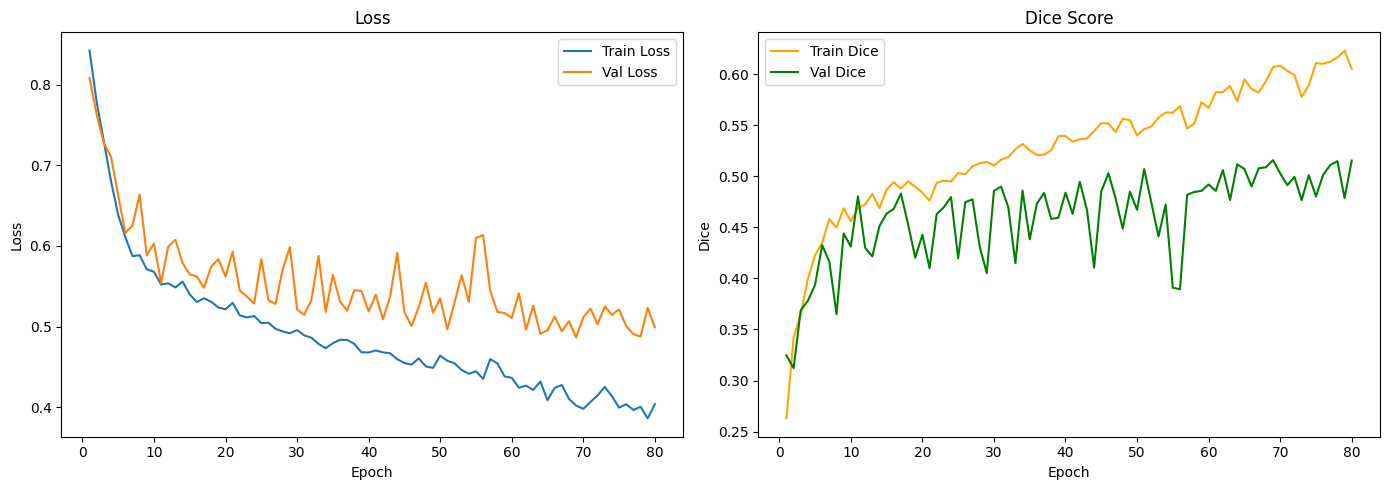

In [ ]:
# plot training/validation loss and training/validation Dice over epochs
epochs = range(1, (NUM_EPOCHS) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
ax1.plot(epochs, history["train_loss"], label="Train Loss")
ax1.plot(epochs, history["val_loss"], label="Val Loss")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

# Dice plot
ax2.plot(epochs, history["train_dice"], label="Train Dice", color="orange")
ax2.plot(epochs, history["val_dice"], label="Val Dice", color="green")
ax2.set_title("Dice Score")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Dice")
ax2.legend()

plt.tight_layout()
plt.show()

### --- Conclusion ---

After finishing the training on our SimpleUNet model we can see the followings:

**Loss graph:**
*   Train Loss decreases smoothly and steadily
*   Val Loss decreases but fluctuates a lot
*   After the 30th epoch the gap between the two loss curves starts to increase, which is a sign of the start of overfitting


---
**Dice graph:**
*   Train Dice increases nicely
*   Val Dice increases but fluctuates a lot - we have to take into consideration that we calculate a mean Dice score for all 6 classes
*   After the 30th epoch the gap between the two dice curves starts to increase, which is a sign of the start of overfitting



---

With the above configuration, the SimpleUNet model reached its best result without overfitting at **Epoch [31/80]**, where the results were the followings:
*   Train Loss: 0.4892 | Train Dice: 0.5162 ||| Val Loss: 0.5145 | Val Dice: 0.4898

After this point the Train-Val Dice gap widens, while the Val Dice gains only slightly: the highest Val Dice of the run (0.5157 at Epoch [69/80]) is therefore mostly a sign of overfitting and noise, not a real improvement.

*While some improvements could be made by adjusting the hyperparameters,
the model's simple architecture limits its ability to achieve more significant
results. Therefore, more complex architecture and data augmentation techniques were followed.*


### --- SimpleUnet predictions ---

In [9]:

# reload the best checkpoint saved during training
checkpoint = torch.load(
    PROJECT_DIR + "/data_root/checkpoints_SimpleUnet/SimpleUNet_30.pth",
    map_location=DEVICE,
    weights_only=False
)
model_SimpleUNet = SimpleUNet(num_classes=6).to(DEVICE)
model_SimpleUNet.load_state_dict(checkpoint["model_state_dict"])

print(f"Model loaded from epoch {checkpoint['epoch']}")
print(f"Best Val Dice: {checkpoint['val_dice']:.4f}")

Model loaded from epoch 31
Best Val Dice: 0.4898


### --- Test set evaluation ---

In [10]:
# quantitative evaluation on the held-out test set
test_loss, test_dice = validate_model(model=model_SimpleUNet, validation_data=test_loader, num_classes=6)
print(f"Test Loss: {test_loss:.4f} | Test Dice: {test_dice:.4f}")

Test Loss: 0.5119 | Test Dice: 0.4926


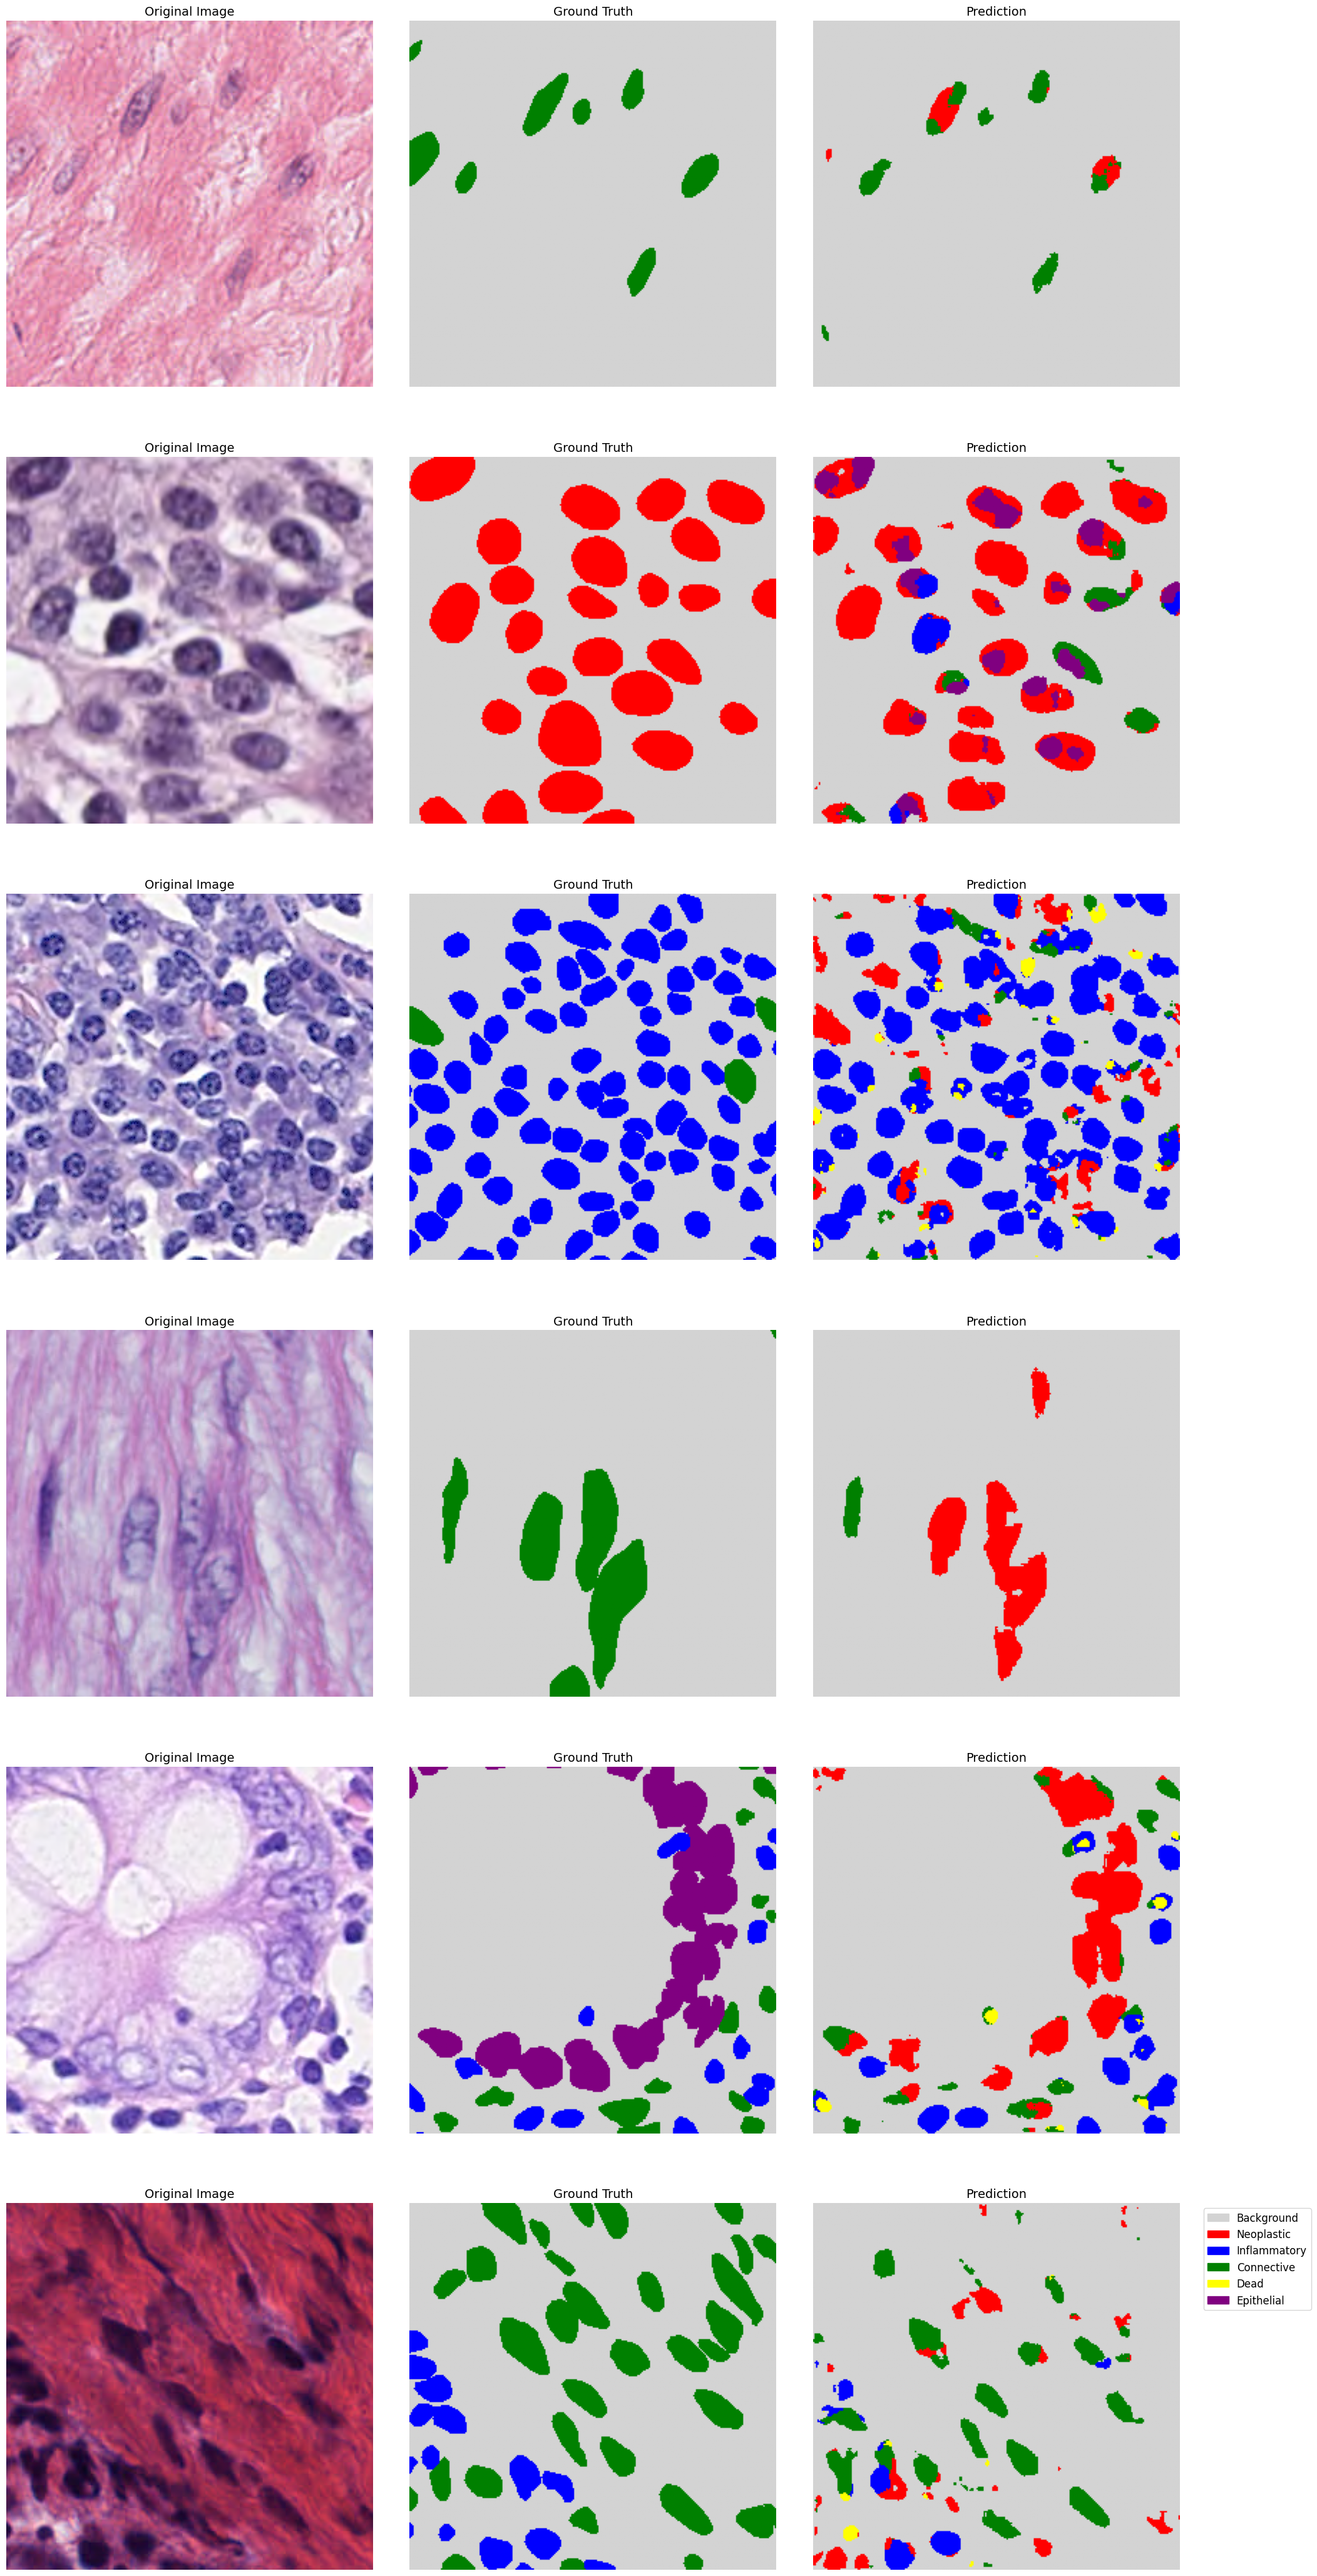

In [11]:
# visualize predictions from the trained baseline model
visualize_predictions(model_SimpleUNet, test_dataset, num_images=6)